# Proyecto Capstone: Clasificación Inteligente de Residuos Reciclables mediante Visión por Computadora (YOLOv11)

## 1. Fase 1: Entendimiento del Negocio (CRISP-DM)

### 1.1 Contexto y Problemática
La baja tasa de valorización de residuos domiciliarios e industriales se debe, en gran medida, a la incorrecta separación en origen por parte de los usuarios (contaminación cruzada en puntos limpios). Automatizar la identificación de materiales reciclables mediante visión artificial permite asistir a los usuarios en tiempo real e incrementar la eficiencia del reciclaje.

### 1.2 Objetivos del Negocio
* **Objetivo General:** Desarrollar e integrar un sistema de detección y clasificación automática de residuos reciclables (**Aluminio**, **Cartón** y **Plástico**) utilizando redes neuronales profundas para facilitar la separación en origen.
* **Objetivos Específicos:**
  1. Construir y curar un dataset etiquetado representativo de las tres clases objetivo.
  2. Entrenar un modelo ligero de detección de objetos capaz de ejecutarse con baja latencia en una aplicación web o dispositivo móvil.

### 1.3 Criterios de Éxito Técnico (Data Mining Goals)
* **Precisión de Detección (`mAP@50`):** Alcanzar un `mAP50` global $\ge 0.65$ en el conjunto de validación/prueba.
* **Velocidad de Inferencia:** Tiempo de inferencia inferior a 100 ms por imagen en GPU/CPU para permitir respuesta casi en tiempo real.

In [2]:
# 1. Instalación de librerías requeridas
!pip install -q roboflow ultralytics opencv-python matplotlib pyyaml

import os
import yaml
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from roboflow import Roboflow

# 2. Descargar dataset desde Roboflow
dataset_path = "/content/Capstone-1"

if not os.path.exists(f"{dataset_path}/data.yaml"):
    print("Descargando dataset desde Roboflow...")
    rf = Roboflow(api_key="SiHqMJp6DHgUgWyZcPV1")
    project = rf.workspace("emanuel-leonardo-mejias-torres").project("capstone-s2mpp")
    version = project.version(1)
    dataset = version.download("yolov11")
    dataset_path = dataset.location
else:
    print("Dataset ya presente en la ruta local.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 28.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 7.1 MB/s eta 0:00:00
Descargando dataset desde Roboflow...
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Capstone-1 in yolov11:: 100%|██████████| 1909/1909 [00:00<00:00, 5368.18it/s]


## 2. Fase 2: Entendimiento de los Datos (EDA)

En esta fase se analiza cuantitativa y visualmente la distribución de clases e instancias en los conjuntos de entrenamiento (`train`) y validación (`valid`), así como las dimensiones relativas de las cajas delimitadoras.

Conteo de objetos en Train: {'Carton': 572, 'Plastico': 568, 'Aluminio': 316}
Conteo de objetos en Valid: {'Aluminio': 16, 'Plastico': 42, 'Carton': 51}


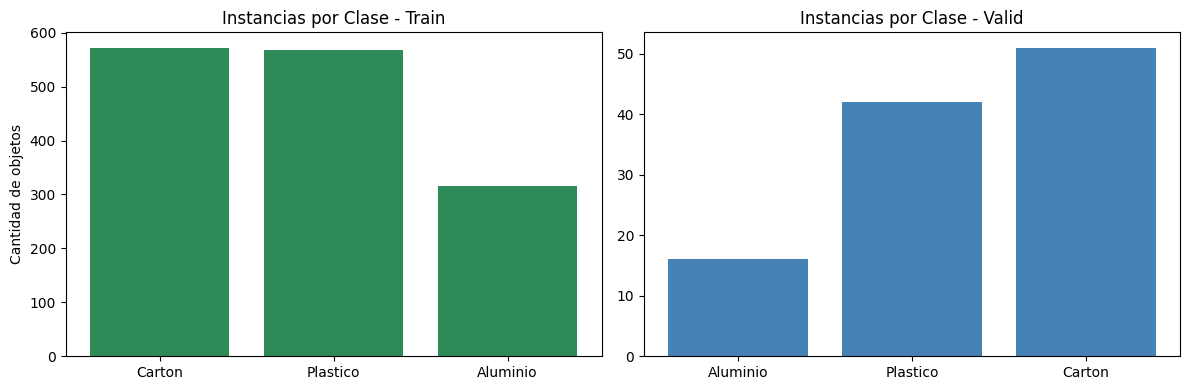

In [3]:
# Leer configuración de clases
with open(f"{dataset_path}/data.yaml", 'r') as f:
    data_yaml = yaml.safe_load(f)

clases = data_yaml['names']

def contar_instancias(split):
    ruta_labels = f"{dataset_path}/{split}/labels"
    conteo = Counter()
    if not os.path.exists(ruta_labels):
        return conteo
    for archivo in os.listdir(ruta_labels):
        if archivo.endswith(".txt"):
            with open(os.path.join(ruta_labels, archivo), 'r') as f:
                for linea in f:
                    partes = linea.strip().split()
                    if partes:
                        clase_id = int(partes[0])
                        nombre_clase = clases[clase_id] if isinstance(clases, list) else clases.get(clase_id, str(clase_id))
                        conteo[nombre_clase] += 1
    return conteo

train_counts = contar_instancias("train")
val_counts = contar_instancias("valid")

print("Conteo de objetos en Train:", dict(train_counts))
print("Conteo de objetos en Valid:", dict(val_counts))

# Visualizar distribución de clases
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(train_counts.keys(), train_counts.values(), color='seagreen')
ax[0].set_title("Instancias por Clase - Train")
ax[0].set_ylabel("Cantidad de objetos")

ax[1].bar(val_counts.keys(), val_counts.values(), color='steelblue')
ax[1].set_title("Instancias por Clase - Valid")
plt.tight_layout()
plt.show()

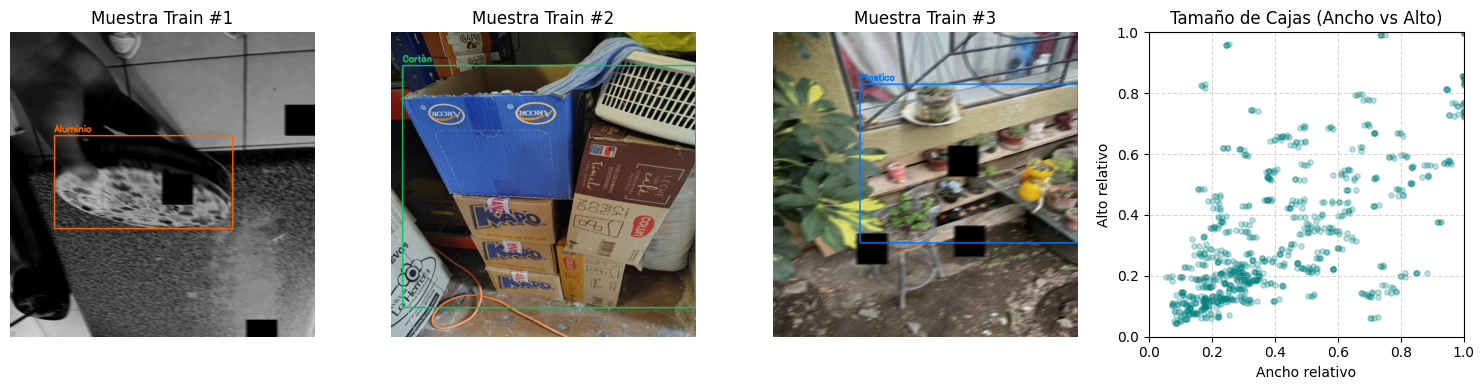

In [4]:
# Inspección Visual y Análisis de Dimensiones de Cajas
anchos, altos = [], []
for txt_file in glob.glob(f"{dataset_path}/train/labels/*.txt"):
    with open(txt_file, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) == 5:
                anchos.append(float(parts[3]))
                altos.append(float(parts[4]))

fig = plt.figure(figsize=(15, 4))
imagenes_muestra = glob.glob(f"{dataset_path}/train/images/*.jpg")[:3]
colores = {0: (255, 100, 0), 1: (0, 200, 100), 2: (0, 120, 255)}

for idx, img_path in enumerate(imagenes_muestra):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    label_path = img_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            for line in f:
                parts = [float(x) for x in line.strip().split()]
                cls_id = int(parts[0])
                nombre_cls = clases[cls_id] if isinstance(clases, list) else clases.get(cls_id, str(cls_id))

                if len(parts) == 5:
                    xc, yc, bw, bh = parts[1], parts[2], parts[3], parts[4]
                    x1, y1 = int((xc - bw/2) * w), int((yc - bh/2) * h)
                    x2, y2 = int((xc + bw/2) * w), int((yc + bh/2) * h)
                else:
                    xs, ys = parts[1::2], parts[2::2]
                    x1, y1 = int(min(xs) * w), int(min(ys) * h)
                    x2, y2 = int(max(xs) * w), int(max(ys) * h)

                cv2.rectangle(img, (x1, y1), (x2, y2), colores.get(cls_id, (255, 255, 0)), 2)
                cv2.putText(img, nombre_cls, (x1, max(y1 - 8, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, colores.get(cls_id, (255, 255, 0)), 2)

    ax = fig.add_subplot(1, 4, idx + 1)
    ax.imshow(img)
    ax.set_title(f"Muestra Train #{idx+1}")
    ax.axis("off")

ax_size = fig.add_subplot(1, 4, 4)
ax_size.scatter(anchos, altos, alpha=0.25, color='teal', s=15)
ax_size.set_title("Tamaño de Cajas (Ancho vs Alto)")
ax_size.set_xlabel("Ancho relativo")
ax_size.set_ylabel("Alto relativo")
ax_size.set_xlim(0, 1)
ax_size.set_ylim(0, 1)
ax_size.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 3. Fase 3: Preparación de Datos

### Corrección de Inconsistencia en Formato de Etiquetas
Se identificó la presencia de anotaciones en formato polígono (segmentación) dentro de las carpetas de etiquetas. Para evitar que el motor de YOLOv11 omita estas muestras durante el entrenamiento de detección, ejecutamos la conversión explícita de polígonos a cajas envolventes (*Bounding Boxes* estandarizadas de 5 valores).

In [5]:
def normalizar_etiquetas_yolo(base_dir):
    convertidos = 0
    total_lineas = 0

    for split in ['train', 'valid', 'test']:
        labels_dir = os.path.join(base_dir, split, 'labels')
        if not os.path.exists(labels_dir):
            continue

        for txt_file in glob.glob(f"{labels_dir}/*.txt"):
            nuevas_lineas = []
            modificado = False

            with open(txt_file, 'r') as f:
                lines = f.readlines()

            for line in lines:
                partes = [float(x) for x in line.strip().split()]
                if not partes:
                    continue

                total_lineas += 1
                cls_id = int(partes[0])

                if len(partes) == 5:
                    nuevas_lineas.append(f"{cls_id} {partes[1]:.6f} {partes[2]:.6f} {partes[3]:.6f} {partes[4]:.6f}\n")
                elif len(partes) > 5:
                    xs = partes[1::2]
                    ys = partes[2::2]
                    min_x, max_x = max(0.0, min(xs)), min(1.0, max(xs))
                    min_y, max_y = max(0.0, min(ys)), min(1.0, max(ys))

                    xc = (min_x + max_x) / 2.0
                    yc = (min_y + max_y) / 2.0
                    w = max_x - min_x
                    h = max_y - min_y

                    nuevas_lineas.append(f"{cls_id} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}\n")
                    modificado = True
                    convertidos += 1

            if modificado:
                with open(txt_file, 'w') as f:
                    f.writelines(nuevas_lineas)

    print(f"Procesamiento finalizado. Total de líneas: {total_lineas}. Polígonos convertidos a Bounding Box: {convertidos}.")

normalizar_etiquetas_yolo(dataset_path)

Procesamiento finalizado. Total de líneas: 1626. Polígonos convertidos a Bounding Box: 695.


## 4. Fase 4: Modelado

Se utiliza el modelo liviano `yolo11n.pt` para realizar Fine-Tuning durante 50 épocas con resolución de entrada de $640 \times 640$ píxeles.

In [6]:
from ultralytics import YOLO

# Cargar modelo base YOLO11 Nano
model = YOLO("yolo11n.pt")

# Entrenamiento de 50 épocas
results = model.train(
    data=f"{dataset_path}/data.yaml",
    epochs=50,
    imgsz=640,
    project="/content/runs/detect",
    name="train_corregido",
    exist_ok=True
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Capstone-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, f

## 5. Fase 5: Evaluación

Se evalúan las métricas obtenidas por el mejor punto de control (`best.pt`) en el conjunto de validación:
* **Precisión Global (`mAP50`):** Se compara frente al objetivo inicial ($\ge 0.65$).
* **Rendimiento por Clase:** Evaluación de recall y precisión individual para **Aluminio**, **Cartón** y **Plástico**.

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1912.7±577.8 MB/s, size: 41.8 KB)
val: Scanning /content/Capstone-1/valid/labels.cache... 61 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 61/61 19.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.8it/s 2.2s
                   all         61        109       0.77      0.444      0.587      0.375
              Aluminio         15         16      0.821      0.375      0.538      0.321
                Carton         32         51      0.829      0.647      0.768       0.57
              Plastico         27         42       0.66       0.31      0.455      0.234
Speed: 6.2ms preprocess, 12.0ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /content/runs/detect/val

--- RESUME

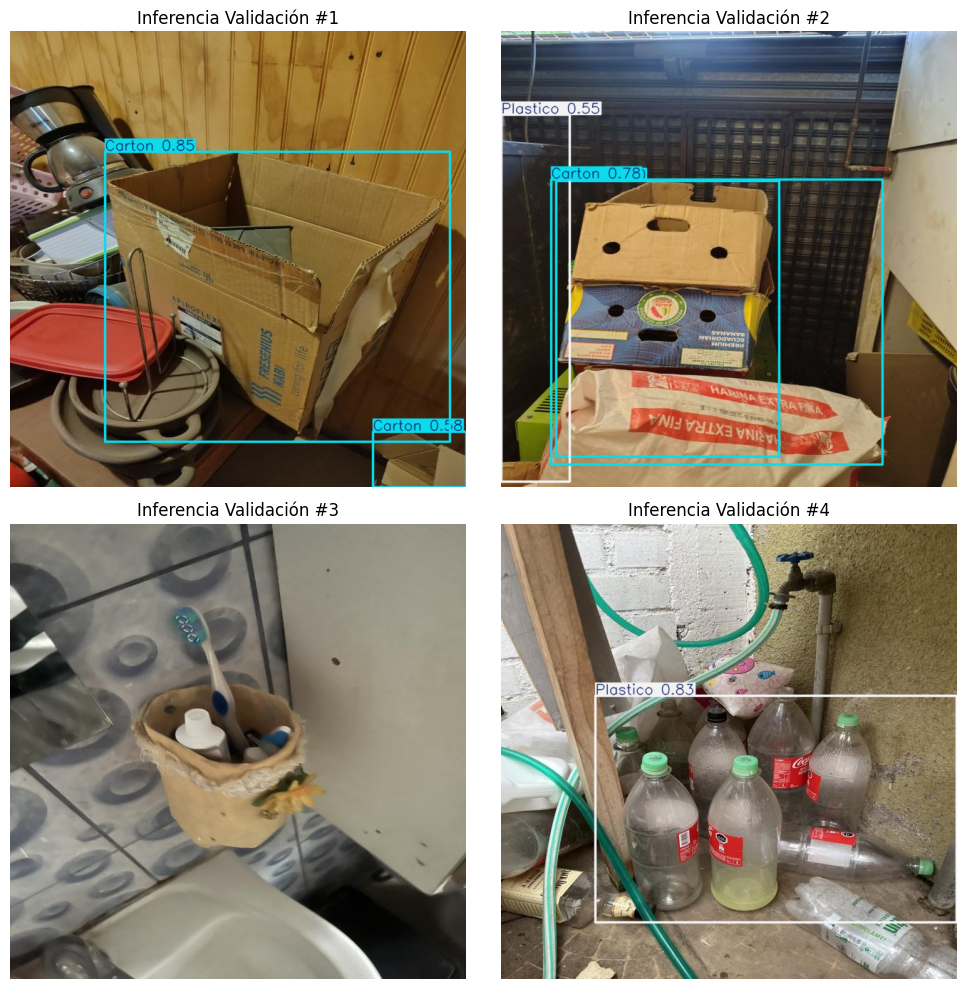

In [7]:
# 1. Cargar el mejor modelo entrenado
best_model_path = "/content/runs/detect/train_corregido/weights/best.pt"
if not os.path.exists(best_model_path):
    best_model_path = "/content/runs/detect/train/weights/best.pt"

best_model = YOLO(best_model_path)

# 2. Ejecutar validación explícita
metrics = best_model.val(data=f"{dataset_path}/data.yaml")

print("\n--- RESUMEN DE MÉTRICAS ---")
print(f"mAP50-95 Global: {metrics.box.map:.4f}")
print(f"mAP50 Global:    {metrics.box.map50:.4f}")

# 3. Mostrar imágenes de inferencia
val_images = glob.glob(f"{dataset_path}/valid/images/*.jpg")[:4]
results_pred = best_model.predict(source=val_images, conf=0.25)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for idx, r in enumerate(results_pred):
    im_bgr = r.plot()
    im_rgb = cv2.cvtColor(im_bgr, cv2.COLOR_BGR2RGB)
    ax = axes[idx // 2, idx % 2]
    ax.imshow(im_rgb)
    ax.set_title(f"Inferencia Validación #{idx+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 6. Fase 6: Despliegue

Se exportan los pesos del modelo al formato estándar **ONNX** para su posterior integración en aplicaciones web, móviles o edge devices.

In [8]:
# Exportar modelo a formato ONNX
onnx_file = best_model.export(format="onnx")
print(f"Modelo exportado exitosamente a ONNX en: {onnx_file}")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from '/content/runs/detect/train_corregido/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (5.3 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 12 packages in 297ms
Prepared 4 packages in 513ms
Installed 4 packages in 35ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.0
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: sl